# 05c · Multi-output Random Forest (bagging baseline)

**Objective.** The project brief names two conventional learners: XGBoost per segment *or* a multi-output Random Forest. Notebook 05 covers boosting; this notebook adds the **bagging** family so that the comparison with the graph models later is not made against a single tree algorithm.

**One forest, four horizons.** A single `RandomForestRegressor` predicts the residuals at 5, 15, 30 and 60 minutes jointly. Every split minimises the *summed* squared error of the four targets, so the horizons share one tree structure (XGBoost fits one model per horizon).

| | XGBoost (notebook 05) | Random Forest (this notebook) |
|---|---|---|
| ensemble idea | boosting: trees fitted one after another on the remaining error | bagging: independent trees on bootstrap samples, averaged |
| loss that drives the splits | absolute error (matches the MAE metric) | squared error (the criterion that supports missing feature values in scikit-learn) |
| outputs | one model per horizon | one model, four outputs |
| missing feature values | native | native (scikit-learn >= 1.4) |
| sensor identity | categorical id + coordinates + training mean | coordinates + training mean (a nominal id would be read as an ordered number) |
| calendar features | of the forecast *target* time | of the *origin* time (one tree serves all horizons) |
| training rows | targets observed at that horizon | targets observed at **all four** horizons |

Both models predict the **residual from the last observed speed**, use the same origins, the same chronological split and the same leakage-free features, and are scored by the same code. Only the training period is used for fitting; the validation period is used for the comparison below and the test period is scored once, in notebook 07a.

> **Provenance.** `RETRAIN = False` reloads the saved forest if it exists and fits it otherwise.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

# Locate the project root (the folder that contains src/config.py) wherever Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

from src import config
config.ensure_dirs()
print(f"project root : .../{ROOT.name}  (absolute paths are not printed)")
print(f"run mode     : {config.RUN_MODE}" + ("   <-- SMOKE TEST: outputs are NOT final results" if config.IS_SMOKE else ""))

project root : .../T005_MLDL_Project  (absolute paths are not printed)
run mode     : full


In [2]:
import json, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance
from src import data_loader as dl, graph_utils as gu, preprocessing as pp, tabular as tb, rf_model as rfm, evaluation as ev, visualization as viz

viz.apply_style()
dl.require_raw_files()
ctx = pp.load_context()
graph = gu.load_graph_artifacts(expected_sensor_ids=ctx.sensor_ids)
N, HZ = len(ctx.sensor_ids), config.HORIZONS
lat, lon = graph.locations["latitude"].to_numpy(), graph.locations["longitude"].to_numpy()
RETRAIN = False     # True: fit the forest again; False: reload the saved forest if it exists (fits it otherwise)
print("random forest parameters:", config.RF_PARAMS)

random forest parameters: {'n_estimators': 150, 'max_features': 0.4, 'min_samples_leaf': 20, 'max_samples': 0.1, 'criterion': 'squared_error', 'n_jobs': -1, 'random_state': 42}


## 1 · Feature matrices and the joint target

In [3]:
td = tb.build_tabular(ctx, lat, lon, train_stride=config.RF_TRAIN_STRIDE, splits=("train", "val", "test"))
X, NAMES = {}, None
for split in td.origin_sets:
    X[split], NAMES = td.flat_matrix(split)
    print(f"{split:6s}: {len(td.origin_sets[split]):6d} origins -> {X[split].shape[0]:>9,} rows x {X[split].shape[1]} features ({X[split].nbytes / 1e6:.0f} MB)")
R_tr, ok_tr, anchor_tr = td.multi_targets("train", HZ)
per_h = {f"{h * 5} min": float(td.targets("train", h)[1].mean()) for h in HZ}
print(f"training rows with ALL four horizons observed: {int(ok_tr.sum()):,} of {len(ok_tr):,} ({ok_tr.mean():.1%}); observed share per horizon: " + ", ".join(f"{k} {v:.1%}" for k, v in per_h.items()))
print("features:", NAMES)
assert "sensor_id" not in NAMES and R_tr.shape == (len(ok_tr), len(HZ))

train :  11941 origins -> 2,471,787 rows x 29 features (287 MB)
val   :   3445 origins ->   713,115 rows x 29 features (83 MB)


test  :   6901 origins -> 1,428,507 rows x 29 features (166 MB)


training rows with ALL four horizons observed: 2,240,515 of 2,471,787 (90.6%); observed share per horizon: 5 min 92.9%, 15 min 92.9%, 30 min 92.8%, 60 min 92.8%
features: ['lag_0', 'lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_5', 'lag_6', 'lag_7', 'lag_8', 'lag_9', 'lag_10', 'lag_11', 'roll_mean_3', 'roll_mean_6', 'roll_mean_12', 'roll_std_6', 'roll_std_12', 'n_observed_window', 'trend_3', 'last_observed', 'age_last_observed', 'sensor_train_mean', 'latitude', 'longitude', 'origin_tod_sin', 'origin_tod_cos', 'origin_dow_sin', 'origin_dow_cos', 'origin_is_weekend']


## 2 · How sensitive is the forest to its main settings?

A baseline is only convincing if it was given a fair chance. Three settings control the bias-variance trade-off of a forest: the **minimum leaf size** (smaller leaves = deeper, lower-bias trees), the **share of features tried at each split** (`max_features`; larger = stronger but more correlated trees) and the **share of rows each tree sees** (`max_samples`). A small grid is fitted with 60 trees each and scored on a validation sample (mean absolute residual error over the four horizons); the best setting is then used for the final 150-tree forest. Only validation data is used.

In [4]:
R_va, ok_va, anchor_va = td.multi_targets("val", HZ)
rng = np.random.default_rng(config.SEED)
pick = np.sort(rng.choice(np.flatnonzero(ok_va), size=min(150_000, int(ok_va.sum())), replace=False))
GRID = [dict(min_samples_leaf=l, max_features=f, max_samples=s) for l, f, s in
        [(20, 0.4, 0.1), (5, 0.4, 0.1), (50, 0.4, 0.1), (20, 0.7, 0.1), (20, 0.4, 0.3), (5, 0.7, 0.3)]][: (6 if not config.IS_SMOKE else 2)]
sens_path = config.METRICS_DIR / f"{config.tagged('rf')}_sensitivity.json"
sens = json.loads(sens_path.read_text()) if (not RETRAIN and sens_path.is_file()) else []
for g in GRID:
    if any(r["params"] == g for r in sens):
        continue
    t0 = time.time()
    m = rfm.fit_forest(X["train"][ok_tr], R_tr[ok_tr], {**config.RF_PARAMS, **g, "n_estimators": 60 if not config.IS_SMOKE else 5})
    err = np.abs(m.predict(X["val"][pick]) - R_va[pick]).mean(axis=0)
    sens.append({"params": g, "val_mae_by_horizon": err.tolist(), "val_mae_mean": float(err.mean()), "seconds": round(time.time() - t0)})
    sens_path.write_text(json.dumps(sens)); del m
    print(f"{g} -> validation residual MAE {err.mean():.4f} mph (mean over horizons), {sens[-1]['seconds']} s")
sens_tbl = pd.DataFrame([{**r["params"], **{f"MAE {h * 5} min": e for h, e in zip(HZ, r["val_mae_by_horizon"])}, "mean MAE": r["val_mae_mean"], "fit s": r["seconds"]} for r in sens]).sort_values("mean MAE")
sens_tbl.to_csv(config.METRICS_DIR / f"{config.tagged('rf')}_sensitivity.csv", index=False)
display(sens_tbl.round(3))
RF_FINAL = {**config.RF_PARAMS, **sens_tbl.iloc[0][["min_samples_leaf", "max_features", "max_samples"]].to_dict()}
RF_FINAL["min_samples_leaf"] = int(RF_FINAL["min_samples_leaf"])
print("selected on validation:", {k: RF_FINAL[k] for k in ("min_samples_leaf", "max_features", "max_samples")})

{'min_samples_leaf': 20, 'max_features': 0.4, 'max_samples': 0.1} -> validation residual MAE 3.1702 mph (mean over horizons), 37 s


{'min_samples_leaf': 5, 'max_features': 0.4, 'max_samples': 0.1} -> validation residual MAE 3.1496 mph (mean over horizons), 34 s


{'min_samples_leaf': 50, 'max_features': 0.4, 'max_samples': 0.1} -> validation residual MAE 3.2113 mph (mean over horizons), 27 s


{'min_samples_leaf': 20, 'max_features': 0.7, 'max_samples': 0.1} -> validation residual MAE 3.1489 mph (mean over horizons), 47 s


{'min_samples_leaf': 20, 'max_features': 0.4, 'max_samples': 0.3} -> validation residual MAE 3.1120 mph (mean over horizons), 95 s


{'min_samples_leaf': 5, 'max_features': 0.7, 'max_samples': 0.3} -> validation residual MAE 3.0853 mph (mean over horizons), 177 s


,min_samples_leaf,max_features,max_samples,MAE 5 min,MAE 15 min,MAE 30 min,MAE 60 min,mean MAE,fit s
5,5,0.7,0.3,2.243,2.810,3.341,3.947,3.085,177
4,20,0.4,0.3,2.252,2.817,3.362,4.016,3.112,95
3,20,0.7,0.1,2.267,2.838,3.400,4.090,3.149,47
1,5,0.4,0.1,2.259,2.840,3.404,4.095,3.150,34
0,20,0.4,0.1,2.271,2.847,3.421,4.141,3.170,37
2,50,0.4,0.1,2.290,2.873,3.463,4.220,3.211,27


selected on validation: {'min_samples_leaf': 5, 'max_features': 0.7, 'max_samples': 0.3}


## 3 · Fit the final forest (or reload it)

In [5]:
fit_path = config.METRICS_DIR / f"{config.tagged('rf')}_fit.json"
if not RETRAIN and rfm.model_path().is_file() and fit_path.is_file():
    forest = rfm.load_model(); fit_info = json.loads(fit_path.read_text())
    print("reloaded the saved forest (fitted in an earlier execution of this notebook)")
else:
    t0 = time.time()
    forest = rfm.fit_forest(X["train"][ok_tr], R_tr[ok_tr], RF_FINAL)
    fit_info = {"train_rows": int(ok_tr.sum()), "n_features": len(NAMES), "feature_names": NAMES, "seconds": round(time.time() - t0),
                "params": {k: str(v) for k, v in RF_FINAL.items()}}
    rfm.save_model(forest); fit_path.write_text(json.dumps(fit_info))
nodes = [t.tree_.node_count for t in forest.estimators_]; depth = [t.tree_.max_depth for t in forest.estimators_]
print(f"{len(forest.estimators_)} trees | mean {np.mean(nodes):,.0f} nodes and depth {np.mean(depth):.1f} per tree | rows per tree {int(float(fit_info['params']['max_samples']) * fit_info['train_rows']):,} | fit time {fit_info['seconds']} s")

150 trees | mean 187,935 nodes and depth 50.7 per tree | rows per tree 672,154 | fit time 403 s


## 4 · Which features does the forest use?

Two importance measures are shown on purpose. *Impurity importance* (MDI) is free but favours features with many distinct values and is computed on the training data. *Permutation importance* measures how much the **validation** MAE of the residual (averaged over the four horizons) grows when one column is shuffled, so it reflects what the fitted forest needs to generalise.

,impurity (MDI) share,permutation: MAE increase (mph),permutation share
last_observed,0.1427,2.2175,0.3124
origin_tod_cos,0.0991,0.7721,0.1088
sensor_train_mean,0.0920,0.7345,0.1035
lag_0,0.0711,0.6561,0.0924
roll_mean_6,0.0315,0.5086,0.0716
roll_mean_12,0.0361,0.4432,0.0624
origin_tod_sin,0.0680,0.3081,0.0434
longitude,0.0418,0.1531,0.0216
latitude,0.0411,0.1381,0.0195
origin_dow_sin,0.0227,0.1205,0.0170


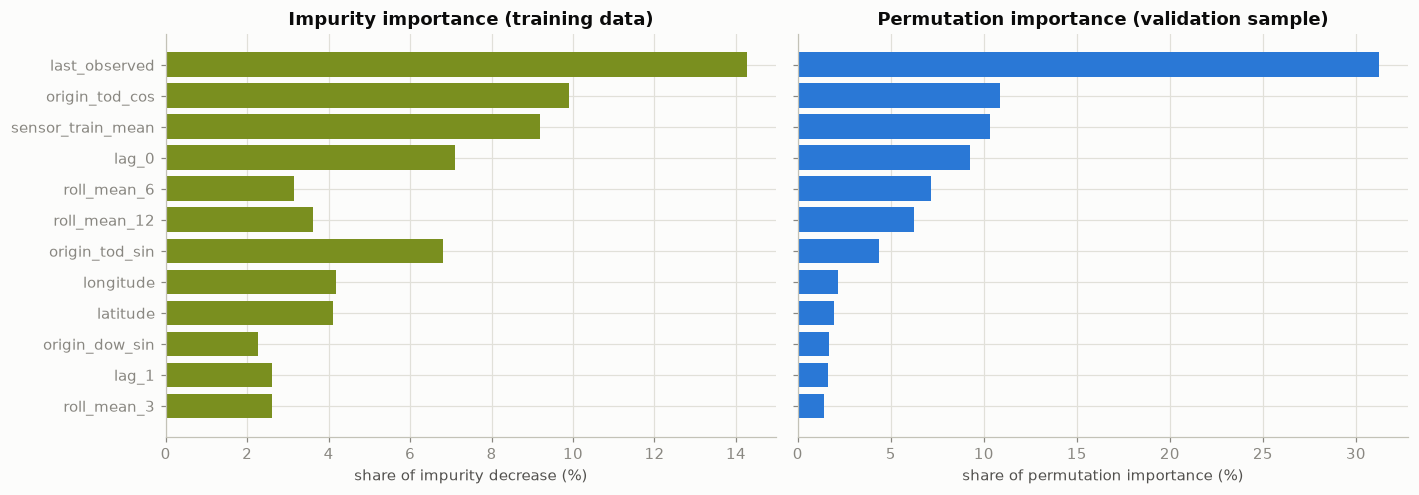

In [6]:
pick_perm = pick[:: max(1, len(pick) // 40_000)]
perm = permutation_importance(forest, X["val"][pick_perm], R_va[pick_perm], scoring="neg_mean_absolute_error", n_repeats=2, random_state=config.SEED, n_jobs=1)
imp = pd.DataFrame({"impurity (MDI) share": pd.Series(forest.feature_importances_, index=NAMES),
                    "permutation: MAE increase (mph)": pd.Series(perm.importances_mean, index=NAMES)})
imp["permutation share"] = imp["permutation: MAE increase (mph)"].clip(lower=0) / imp["permutation: MAE increase (mph)"].clip(lower=0).sum()
imp.sort_values("permutation share", ascending=False).to_csv(config.METRICS_DIR / f"{config.tagged('rf')}_feature_importance.csv")
top = imp.sort_values("permutation share", ascending=False).head(12)
display(top.round(4))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
order = top.index[::-1]
axes[0].barh(order, imp.loc[order, "impurity (MDI) share"] * 100, color="#7a8f1f"); axes[0].set_xlabel("share of impurity decrease (%)"); axes[0].set_title("Impurity importance (training data)")
axes[1].barh(order, imp.loc[order, "permutation share"] * 100, color="#2a78d6"); axes[1].set_xlabel("share of permutation importance (%)"); axes[1].set_title("Permutation importance (validation sample)")
fig.tight_layout(); viz.save_figure(fig, "05c_rf_feature_importance"); plt.show()

## 5 · Forecast all validation and test origins and save

In [7]:
preds = {}
for split in ("val", "test"):
    o = td.origin_sets[split]
    anchor = td.base[split][:, td.anchor_col]
    flat = rfm.predict_speed(forest, X[split], anchor)                       # [S * N, H]
    out = flat.reshape(len(o), N, len(HZ)).transpose(0, 2, 1).copy()           # [S, H, N]
    assert np.isfinite(out).all()
    preds[split] = out                                                        # raw output; clipping to 0..70 mph happens when scoring
    ev.save_predictions("random_forest", split, out, o, HZ, {"model": "random_forest", "run_mode": config.RUN_MODE, "units": "mph", "seed": config.SEED})
    print(split, out.shape, "= [samples, horizons, sensors] mph | range", round(float(out.min()), 1), "to", round(float(out.max()), 1))

val (3445, 4, 207) = [samples, horizons, sensors] mph | range 2.8 to 70.0


test (6901, 4, 207) = [samples, horizons, sensors] mph | range 1.4 to 70.0


## 6 · Validation results (the test period is not scored here)

MAE                    RMSE                     MAPE         \
horizon_min      5     15    30    60    5     15    30    60     5      15   
model                                                                         
persistence    2.64  3.24  3.84  4.84  4.38  6.03  7.54  9.67   5.93   7.83   
random_forest  2.26  2.84  3.35  3.96  3.83  5.20  6.19  7.20   5.40   7.51   
seasonal_avg   4.32  4.32  4.33  4.33  8.07  8.07  8.08  8.08  12.62  12.63   
xgboost        2.16  2.64  3.05  3.50  3.83  5.26  6.29  7.22   5.15   7.03   

                             
horizon_min       30     60  
model                        
persistence     9.88  13.20  
random_forest   9.44  11.70  
seasonal_avg   12.64  12.65  
xgboost         8.89  10.83

valid validation targets: 2,659,512 | models compared: ['random_forest', 'persistence', 'seasonal_avg', 'xgboost']


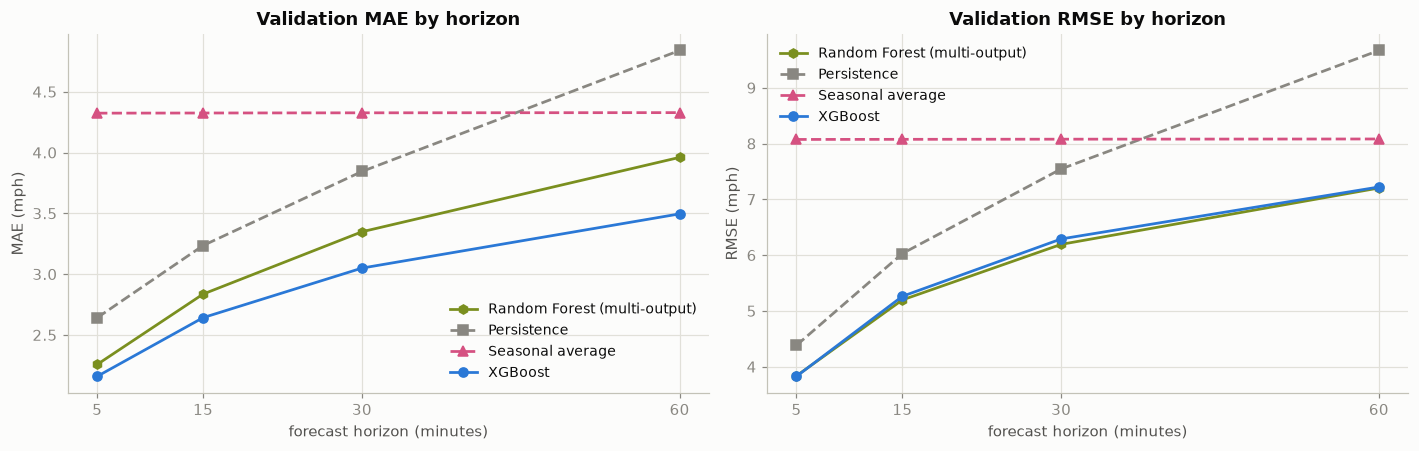

In [8]:
others = [m for m in ("persistence", "seasonal_avg", "xgboost") if ev.prediction_path(m, "val").is_file()]
val_preds = {"random_forest": ev.clip_predictions(preds["val"])}
for m in others:
    d = ev.load_predictions(m, "val")
    assert np.array_equal(d["origins"], td.origin_sets["val"]) and d["horizons"] == HZ
    val_preds[m] = d["pred"]
yv, mv = pp.gather_targets(ctx.speed, ctx.mask, td.origin_sets["val"], HZ)
valid = ev.common_valid_mask(val_preds, mv)
table = ev.metrics_by_horizon(val_preds, yv, valid, HZ)
table.to_csv(config.METRICS_DIR / f"{config.tagged('random_forest')}_metrics_val.csv", index=False)
display(table.pivot(index="model", columns="horizon_min", values=["MAE", "RMSE", "MAPE"]).round(2))
print(f"valid validation targets: {int(valid.sum()):,} | models compared: {list(val_preds)}")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
viz.plot_metric_vs_horizon(axes[0], table, "MAE", list(val_preds), title="Validation MAE by horizon")
viz.plot_metric_vs_horizon(axes[1], table, "RMSE", list(val_preds), title="Validation RMSE by horizon")
fig.tight_layout(); viz.save_figure(fig, "05c_rf_val_horizon"); plt.show()

## 7 · Generalisation gap

A flexible learner can look good on the data it was fitted to. The in-sample residual error on a training sample is compared with the validation error: a large gap would mean the forest memorises the training weeks (note that a forest's in-sample error is optimistic because each row is seen by the trees that were fitted on it).

In [9]:
pick_tr = np.sort(rng.choice(np.flatnonzero(ok_tr), size=min(150_000, int(ok_tr.sum())), replace=False))
tr_pred = forest.predict(X["train"][pick_tr])
rows = []
for j, h in enumerate(HZ):
    rows.append({"horizon_min": h * 5, "train MAE of residual (mph)": float(np.abs(tr_pred[:, j] - R_tr[pick_tr, j]).mean()),
                 "validation MAE of residual (mph)": float(np.abs(forest.predict(X["val"][pick])[:, j] - R_va[pick, j]).mean())})
gap = pd.DataFrame(rows).set_index("horizon_min")
gap["ratio val / train"] = gap.iloc[:, 1] / gap.iloc[:, 0]
display(gap.round(3))

,train MAE of residual (mph),validation MAE of residual (mph),ratio val / train
horizon_min,,,
5,2.083,2.238,1.074
15,2.551,2.802,1.098
30,2.920,3.331,1.141
60,3.339,3.936,1.179


In [10]:
t = table.pivot(index="horizon_min", columns="model", values="MAE")
claims = {}
if "persistence" in t:
    claims["the forest beats persistence at every horizon on validation"] = bool((t["random_forest"] < t["persistence"]).all())
if "xgboost" in t:
    claims["XGBoost has the lower validation MAE than the forest at every horizon"] = bool((t["xgboost"] < t["random_forest"]).all())
    gain = (100 * (t["xgboost"] - t["random_forest"]) / t["xgboost"]).round(1)
    print("forest MAE relative to XGBoost (%; positive = forest is better):", gain.to_dict())
display(ev.report_claims(claims))

forest MAE relative to XGBoost (%; positive = forest is better): {5: -4.5, 15: -7.3, 30: -9.8, 60: -13.3}


,claim,holds in this run
0,the forest beats persistence at every horizon ...,True
1,XGBoost has the lower validation MAE than the ...,True
